# Analysis of Covid-19 papers

**Master:** Physics of Data \
**Course:** Management and Analysis of Physics Dataset - Module B (MAPD-B) \
**Professor:** Jacopo Pazzini \
**Students:** Polina Gridiaeva, Andres David Rojas Lozano, Elena Niero, Gabriela Landinez Rangel

## Task 4: Cosine Similarity

### Spark set up

In [1]:
# Import the python libraries to create/connect to a Spark Session
from pyspark.sql import SparkSession

# Define the number of executors and number of cores for each one
executor_instances = 3
executor_cores = 8

# Build the spark session
spark = SparkSession.builder \
    .master("spark://master:7077") \
    .appName("COVID-19 task 4") \
    .config("spark.jars.packages", "org.apache.hadoop:hadoop-common:3.3.4,org.apache.hadoop:hadoop-aws:3.3.4") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")\
    .config("spark.sql.execution.arrow.pyspark.fallback.enabled", "false")\
    .config('spark.hadoop.fs.s3a.aws.credentials.provider', 'org.apache.hadoop.fs.s3a.SimpleAWSCredentialsProvider')\
    .config("spark.hadoop.fs.s3a.access.key", "ACCESS_KEY") \
    .config("spark.hadoop.fs.s3a.secret.key", "SECRET_KEY") \
    .config('spark.hadoop.fs.s3a.endpoint', 'https://cloud-areapd.pd.infn.it:5210')\
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .config("spark.hadoop.fs.s3a.metadatastore.impl", "org.apache.hadoop.fs.s3a.s3guard.NullMetadataStore") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.fs.s3a.connection.ssl.enabled","false") \
    .config("com.amazonaws.sdk.disableCertChecking","true") \
    .config("spark.executor.instances", str(executor_instances)) \
    .config("spark.executor.cores", str(executor_cores)) \
    .config("spark.cores.max", str(executor_instances * executor_cores)) \
    .config("spark.executor.memory", "10g") \
    .getOrCreate()

# Create a spark context and print its status
sc = spark.sparkContext
sc

:: loading settings :: url = jar:file:/mnt/vol2/env/jup_env/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/ubuntu/.ivy2.5.2/cache
The jars for the packages stored in: /home/ubuntu/.ivy2.5.2/jars
org.apache.hadoop#hadoop-common added as a dependency
org.apache.hadoop#hadoop-aws added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-1650d7bc-68ee-4b61-83fb-4c01d4cec2d9;1.0
	confs: [default]
	found org.apache.hadoop#hadoop-common;3.3.4 in central
	found org.apache.hadoop.thirdparty#hadoop-shaded-protobuf_3_7;1.1.1 in central
	found org.apache.hadoop#hadoop-annotations;3.3.4 in central
	found org.apache.hadoop.thirdparty#hadoop-shaded-guava;1.1.1 in central
	found com.google.guava#guava;27.0-jre in central
	found com.google.guava#failureaccess;1.0 in central
	found com.google.guava#listenablefuture;9999.0-empty-to-avoid-conflict-with-guava in central
	found com.google.cod

<SparkContext master=spark://master:7077 appName=COVID-19 cosine gaby>

### Import all the other libraries

In [2]:
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Construct the embedding matrix

In [3]:
# Specify the path where the file containing the embeddings for all paper titles is located
input_file = "/mnt/vol2/.cache/kagglehub/paper_embeddings.jsonl"

# Create empty lists where we are going to save the titles, ids and embeddings for each paper
ids = []
titles = []
embeddings = []

# Open each file in the path and for each line in it we extract the paper_id, title_name, and embedding
with open(input_file) as f:
    for line in f: 
        parsed_line = json.loads(line) 
        ids.append(parsed_line["paper_id"])
        titles.append(parsed_line["title_name"])
        embeddings.append(parsed_line["embedding"])
        
# Convert the list of embeddings into a numpy array
emb_matrix = np.array(embeddings, dtype=np.float32)
print(emb_matrix.shape)

(128547, 300)


Cosine similarity measures how aligned two vectors are by calculating the cosine of the angle between them. It is defined as
$$cos(a,b) = \frac{a \cdot b}{|a||b|}.$$
If we normalize the vector first, the formula simplifies to:
$$cos(a,b) = \hat{a} \cdot \hat{b},$$
which can actually be computed for many vectors through a matrix multiplication.

The dot product between every pair of unit vectors is equivalent to the pairwise multiplication of the rows of a normalized matrix by its own transpose:
$$S = \hat{A} \cdot \hat{A}^T$$
where $\hat{A}$ is the matrix of normalized embeddings and $S$ is the resulting similarity matrix, with $S_{ij}$ representing the cosine similarity between paper $i$ and paper $j$.

In [5]:
# Compute the magnitude of each embedding by specifying axis=1 for the embedding matrix
norms = np.linalg.norm(emb_matrix, axis=1, keepdims=True) 

# Calculate the normalized embedding matrix by dividing each row of emb_matrix by its own norm 
emb_normalized = emb_matrix / norms 

### Broadcasting

In [6]:
# Broadcast the normalized matrix to all executors
bc_matrix = sc.broadcast(emb_normalized)

The normalized matrix is broadcasted, but we still need to split the papers into blocks, so that during each task the cosine similarity is computed for a manageable amount of papers. We will define a variable called `block_size` to define how many papers are processed per task, and split the range of paper indexes into chunks of that size. 

In [7]:
# Here we split papers into blocks for parallel processing

#block_size = 2000 # number of titles processed per task
block_size = 1000 

N = emb_normalized.shape[0] # number of rows (papers)
all_indexes = range(N) # all indexes from 0 to N-1
index_blocks = [] # a list of lists to store each block of indexes

for i in range(0, N, block_size):
    block = list(all_indexes[i:i + block_size])
    index_blocks.append(block)

len(index_blocks) # total number of blocks

129

Now we can use `parallelize()` to take this python collection (index blocks) and turn it into an RDD (Resilient Distributed Dataset), so that each partition can be processed independently and in parallel across \
the available executors.

In [8]:
# For the first trial we will set numSlices equal to the number of blocks, so that we have one partition per block
blocks_rdd = sc.parallelize(index_blocks, numSlices=len(index_blocks))

Finally, we define a function `process_block` in which the cosine similarity is computed between each paper of the given block and every other paper in the dataset. For each paper in the block, we keep only the top K most similar and K most dissimilar papers using the numpy function argpartition.

It is important to keep in mind that each task will only receive a subset of paper indexes (idx_block). Therefore we need to distinguis between local and global indexes: local_i is the position within that subset (0, ... up to block_size - 1), while global_i is the original paper index from the full dataset (0, ... 128547), used to identify which paper the result actually belongs to when we later collect results from all blocks. `enumerate(idx_block)` gives us both at once: local_i to read the right row of similarity_matrix, and global_i to correctly label that row's results back in the context of the whole dataset.

In [9]:
K = 5  # how many most similar (or dissimilar) papers keep 

def process_block(idx_block):
    full_matrix = bc_matrix.value 
    block_matrix = full_matrix[idx_block]  # shape (block_size, 300)
    similarity_matrix = block_matrix @ full_matrix.T   # (block_sizex300) @ (300x128547) = block_sizex128547

    results = []

    # for each paper (row) we only store its top K most similar and K most dissimilar papers
    for local_i, global_i in enumerate(idx_block):
        
        row = similarity_matrix[local_i] # cosine similarity for local_i against all other papers
  
        top_idx = np.argpartition(row, -K)[-K:]      # most similar
        bottom_idx = np.argpartition(row, K)[:K]     # most dissimilar

        top = [(int(j), float(row[j])) for j in top_idx] 
        bottom = [(int(j), float(row[j])) for j in bottom_idx]
        
        results.append((global_i, top, bottom)) 
        
    return results

### Flat Map, caching and count

In [10]:
results_rdd = blocks_rdd.flatMap(process_block)
results_rdd.persist()
print(f"Total papers that have been processed: {results_rdd.count()}")

[Stage 0:====================================================>  (123 + 6) / 129]

Total papers that have been processed: 128547


### Final results

In [11]:
num = 1
#samples = results_rdd.take(num)  # bring the first num tuples (one per paper) back to the driver
samples = results_rdd.takeSample(False, num, seed=123456)

In [16]:
# top/bottom are unsorted (argpartition only guarantees that they are the top 5 or bottom 5)
# we sort them here just for display

for global_i, top, bottom in samples:
    
    print(f"Paper id: {ids[global_i]}")
    print(f"Title: {titles[global_i]}")
    
    # top/bottom are unsorted (argpartition only guarantees they're the top/bottom K)
    # we sort them here just for fancy printing
    top_sorted = sorted(top, key=lambda x: x[1], reverse=True)
    bottom_sorted = sorted(bottom, key=lambda x: x[1])

    top_df = pd.DataFrame(
    [(score, ids[idx], titles[idx]) for idx, score in top_sorted if idx != global_i], #[:3], # we take the top 3 and exclude itself
    columns=["Score", "Paper id", "Paper title"])
    
    bottom_df = pd.DataFrame(
        [(score, ids[idx], titles[idx]) for idx, score in bottom_sorted],
        columns=["Score", "Paper id", "Paper title"])

pd.set_option('display.max_colwidth', None)
top_df

Paper id: PMC7112792
Title: Development of a real-time TaqMan® RT-PCR assay for the detection of infectious bronchitis virus in chickens, and comparison of RT-PCR and virus isolation


,Score,Paper id,Paper title
0,1.00000,df0c41998e31603d157707d4acfc7bad63e0afd7,"Development of a real-time TaqMan ® RT-PCR assay for the detection of infectious bronchitis virus in chickens, and comparison of RT-PCR and virus isolation"
1,0.98264,8d4b026fa5fc8924284bdfb3922b9cb27b1038a5,Development and evaluation of a real-time Taqman RT-PCR assay for the detection of infectious bronchitis virus from infected chickens
2,0.96091,PMC4634283,Detection of influenza C virus by a real‐time RT‐PCR assay
3,0.96091,cc0ab9e7e36f5c28b6bafc358a8236c05a1ca415,Detection of influenza C virus by a real-time RT-PCR assay


**Important comments**

From the previous results, it is important to highlight that the row 0, which contains the top result scores 1.0 as if it were the same paper. The above is because it indeed has a near-identical title but a different paper_id. In rows 2 and 3, something similar happens, both papers have identical scores and titles but different paper_ids. 

This confirms the problem we anticipated when cleaning the dataset, and even if duplicates were cleaned during the pre-processing of data, we still face a near-duplicate issue, since the dataset was built with different paper_ids for the same titles.

Based on this, we propose to use the cosine similarity to identify the near-duplicates that were missed during the cleaning (either because titles were slightly different or because the paper_ids were different). Any pair scoring close to 1.0 is very likely the same underlying paper, regardless of whether the paper_ids differ.

### Using the cosine similarity to identify duplicates

In [95]:
threshold = 1.0 # to consider near-duplicates papers

def identify_duplicates(record):
    
    global_i, top, bottom = record # record from the results_rdd
    pairs = [] # empty list to store the duplicate pairs
    
    for idx, score in top:
        
        if idx != global_i and score >= threshold:

            #pair = (global_i, idx)
            pair = (min(global_i, idx), max(global_i, idx)) # this to avoid repeated records after 
            pairs.append((score, pair))
            
    return pairs

In [96]:
duplicates_rdd = results_rdd.flatMap(identify_duplicates).distinct()

In [97]:
n = 10
top_duplicates = duplicates_rdd.takeOrdered(n, key=lambda x: -x[0])

duplicates_df = pd.DataFrame(
    [(score, ids[i], ids[j], titles[i], titles[j]) for score, (i, j) in top_duplicates],
    columns=["Similarity", "Paper id A", "Paper id B", "Title A", "Title B"])

duplicates_df

,Similarity,Paper id A,Paper id B,Title A,Title B
0,1.000001,29f3e0a47f515a79830a5ba90f789fa3a561c391,PMC7323081,Coronavirus Disease 2019 (COVID-19): Potential implications for weak health systems and conflict zones in the Middle East and North Africa region,Coronavirus Disease 2019 (COVID‐19): Potential implications for weak health systems and conflict zones in the Middle East and North Africa region
1,1.000001,a47eafce2e7e546cc5898ad7317014cce0aa017e,PMC7161821,"Disturbance regimes, gap-demanding trees and seed mass related to tree height in warm temperate rain forests worldwide","Disturbance regimes, gap‐demanding trees and seed mass related to tree height in warm temperate rain forests worldwide"
2,1.000001,11a705945a53bd76448c88438baeb0ebd2c5c2c6,299d71dfb14e47a63024dea292f2ecf6b94bd8fd,ll Article Billions in Misspent EU Agricultural Subsidies Could Support the Sustainable Development Goals,Article Billions in Misspent EU Agricultural Subsidies Could Support the Sustainable Development Goals
3,1.000001,68f9d17b3481fc9b2466a48716d7e977ca9bbfad,3230a822ceaf337c5137d32e1505878910621991,Send Orders of Reprints at bspsaif@emirates.net.ae 104 The Open Virology Journal,Send Orders of Reprints at bspsaif@emirates.net.ae The Open Virology Journal
4,1.000001,437e707d3a46c8dfa75473a3975d75e6bb946be9,PMC7347254,Transpulmonary pressure in SARS-CoV-2- associated acute respiratory distress syndrome: a single-center observational study,Transpulmonary pressure in SARS-CoV-2-associated acute respiratory distress syndrome: a single-center observational study
5,1.000001,4a639e0661b41b63ac1a947f2eec28daa67eefb2,PMC7110734,"Emerging and re-emerging viruses in Malaysia, 1997-2007","Emerging and re-emerging viruses in Malaysia, 1997–2007"
6,1.000001,f180c7b3219be619b203f37dcc1d99c144d7833c,PMC7181401,Protect Healthcare Workers and Patients from COVID- 19: The Experience of Two Tertiary Ophthalmology Care Referral Centers in Italy,Protect Healthcare Workers and Patients from COVID-19: The Experience of Two Tertiary Ophthalmology Care Referral Centers in Italy
7,1.000001,0cbb0d4d0807121001fe5a335b9a230158c7fcb5,PMC7267637,Coagulopathy of COVID-19 and antiphospholipid antibodies,Coagulopathy of COVID‐19 and antiphospholipid antibodies
8,1.000001,0f0668bf66fa39ed383ff351452c2d510735ab0b,PMC7457622,Rethinking Remdesivir: Synthesis of Lipid Prodrugs that Substantially Enhance Anti-Coronavirus Activity 2 3 4 5,Rethinking Remdesivir: Synthesis of Lipid Prodrugs that Substantially Enhance Anti-Coronavirus Activity
9,1.000001,e35025865bbd696c5a5f4c65f46df234458dbd4a,PMC7159570,Epidemiology and Immediate Indirect Effects of Respiratory Viruses in Lung Transplant Recipients: A 5-Year Prospective Study,Epidemiology and Immediate Indirect Effects of Respiratory Viruses in Lung Transplant Recipients: A 5‐Year Prospective Study


### Benchmarking

Once the process baseline was established, we proceeded to iterate over the pipeline using different configurations for the number of partitions in the `parallelize` method. We tested multiple values relative to the total number of available cores ($x$), specifically using $[1/3x, 2/3x, x, 2x, 4x, 8x]$. This benchmark was repeated across different cluster configurations of executors and cores, keeping the total core count constant at 24:

* 3 executors with 8 cores each
* 6 executors with 4 cores each
* 12 executors with 2 cores each

To ensure statistical reliability, we measured the average execution time across multiple runs ($n=5$) for each specific configuration, allowing for a subsequent analysis and comparison between the runs.

In [23]:
partitions_to_test= [8, 12, 24, 48, 72, len(index_blocks)]
n_repeats = 5
all_results = []

for num_of_partitions in partitions_to_test:
    blocks_rdd = sc.parallelize(index_blocks, numSlices=num_of_partitions).persist()
    
    for rep in range(n_repeats):
        start = time.time()
        results_rdd = blocks_rdd.flatMap(process_block).persist()
        results_rdd.count()
        elapsed = time.time() - start
        
        print(f"numSlices={num_of_partitions} rep={rep+1} time={elapsed:.2f}s")
        
        all_results.append({
            "num_partitions": num_of_partitions,
            "rep": rep,
            "time_sec": elapsed
        })
        
        results_rdd.unpersist(blocking=True)
    blocks_rdd.unpersist(blocking=True)

df = pd.DataFrame(all_results)
df.to_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task4_3x8.csv", index=False)
print(df)

numSlices=8 rep=1 time=21.80s


numSlices=8 rep=2 time=20.30s


numSlices=8 rep=3 time=20.46s


numSlices=8 rep=4 time=20.60s


numSlices=8 rep=5 time=19.91s


...

numSlices=129 rep=2 time=11.91s


numSlices=129 rep=3 time=11.40s


numSlices=129 rep=4 time=11.56s


[Stage 61:=====================================================>(128 + 1) / 129]

numSlices=129 rep=5 time=11.64s
    num_partitions  rep   time_sec
0                8    0  21.800527
1                8    1  20.298215
2                8    2  20.464396
3                8    3  20.599253
4                8    4  19.908031
5               12    0  24.232982
6               12    1  23.572945
7               12    2  23.272271
8               12    3  22.869562
9               12    4  22.795930
10              24    0  14.757492
11              24    1  15.106190
12              24    2  14.401317
13              24    3  14.330910
14              24    4  14.411493
15              48    0  12.425738
16              48    1  12.325733
17              48    2  12.319641
18              48    3  12.350882
19              48    4  12.483595
20              72    0  10.922866
21              72    1  11.168963
22              72    2  10.911356
23              72    3  10.856810
24              72    4  10.816459
25             129    0  11.562278
26             129    1

In [ ]:
df = pd.read_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task4_3x8.csv")
#df = df[df['rep'] > 0]  

df_avg = df.groupby('num_partitions')['time_sec'].mean().reset_index()
partition_ticks = [8, 12, 24, 48, 72, len(index_blocks)]

plt.figure(figsize=(10, 5))
plt.plot(df_avg['num_partitions'], df_avg['time_sec'], marker='o', color='darkorange')
plt.xticks(partition_ticks)
plt.xlabel('Number of partitions')
plt.ylabel('Execution time (s)')
plt.title('Benchmarking for Cosine Similarity')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

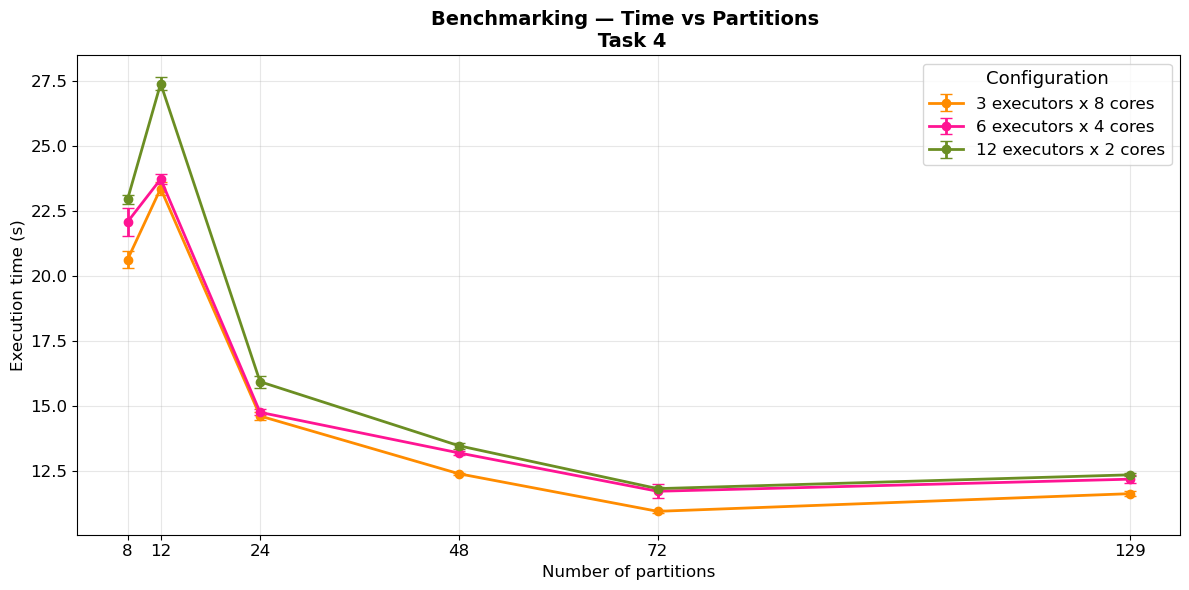

In [6]:
df1 = pd.read_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task4_3x8.csv")
df2 = pd.read_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task4_6x4.csv")
df3 = pd.read_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task4_12x2.csv")

df1_avg = df1.groupby('num_partitions')['time_sec'].agg(mean_time='mean', sem_time='sem').reset_index()
df2_avg = df2.groupby('num_partitions')['time_sec'].agg(mean_time='mean', sem_time='sem').reset_index()
df3_avg = df3.groupby('num_partitions')['time_sec'].agg(mean_time='mean', sem_time='sem').reset_index()

partition_ticks = [8, 12, 24, 48, 72, len(index_blocks)]

plt.figure(figsize=(12, 6))
plt.errorbar(df1_avg['num_partitions'], df1_avg['mean_time'], yerr=df1_avg['sem_time'],
             marker='o', color='darkorange', label='3 executors x 8 cores', linewidth=2, capsize=4)
plt.errorbar(df2_avg['num_partitions'], df2_avg['mean_time'], yerr=df2_avg['sem_time'],
             marker='o', color='deeppink', label='6 executors x 4 cores', linewidth=2, capsize=4)
plt.errorbar(df3_avg['num_partitions'], df3_avg['mean_time'], yerr=df3_avg['sem_time'],
             marker='o', color='olivedrab', label='12 executors x 2 cores', linewidth=2, capsize=4)

plt.xticks(partition_ticks, fontsize = 12)
plt.yticks(fontsize = 12)
plt.xlabel('Number of partitions', fontsize = 12)
plt.ylabel('Execution time (s)', fontsize = 12)
plt.title('Benchmarking — Time vs Partitions \n Task 4', fontsize = 14, fontweight = 'bold')
plt.legend(title='Configuration', fontsize = 12, title_fontsize = 13)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('/mnt/vol2/.cache/kagglehub/benchmarking_csv/plots_new_version/benchmark_plot_task4.png', dpi=150)
plt.show()

In [1]:
spark.stop()

NameError: name 'spark' is not defined